In [12]:
from pathlib import Path
import json
import pandas as pd

# Automatically resolve project root whether running from root or notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
raw_dir = PROJECT_ROOT / "data" / "raw"
processed_dir = PROJECT_ROOT / "data" / "processed"
interim_dir = PROJECT_ROOT / "data" / "interim"

df_train = pd.read_json(raw_dir / "train.jsonl", lines=True)
df_shared_task = pd.read_json(raw_dir / "shared_task_dev.jsonl", lines=True)


def print_df_info(df: pd.DataFrame, name: str):
    print(f"{name} DataFrame:")
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    print(f"Missing values:\n{df.isnull().sum()}\n")
    print(f"Data types:\n{df.dtypes}\n")
    
    # Check duplicates on hashable columns (and full row via string casting)
    print(f"Duplicate IDs: {df.duplicated(subset=['id']).sum()}")
    print(f"Duplicate claims: {df.duplicated(subset=['claim']).sum()}")
    print(f"Exact duplicate rows: {df.astype(str).duplicated().sum()}\n")
    
    print("Info:")
    df.info()
    print(f"\nFirst 5 rows:\n{df.head()}\n")


print_df_info(df_train, "Training")
print("=" * 50)
print_df_info(df_shared_task, "Shared Task Dev")

Training DataFrame:
Shape: (145449, 5)
Columns: ['id', 'verifiable', 'label', 'claim', 'evidence']
Missing values:
id            0
verifiable    0
label         0
claim         0
evidence      0
dtype: int64

Data types:
id             int64
verifiable       str
label            str
claim            str
evidence      object
dtype: object

Duplicate IDs: 0
Duplicate claims: 9904
Exact duplicate rows: 0

Info:
<class 'pandas.DataFrame'>
RangeIndex: 145449 entries, 0 to 145448
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   id          145449 non-null  int64 
 1   verifiable  145449 non-null  str   
 2   label       145449 non-null  str   
 3   claim       145449 non-null  str   
 4   evidence    145449 non-null  object
dtypes: int64(1), object(1), str(3)
memory usage: 15.0+ MB

First 5 rows:
       id      verifiable            label  \
0   75397      VERIFIABLE         SUPPORTS   
1  150448      VERIFIABLE         SU

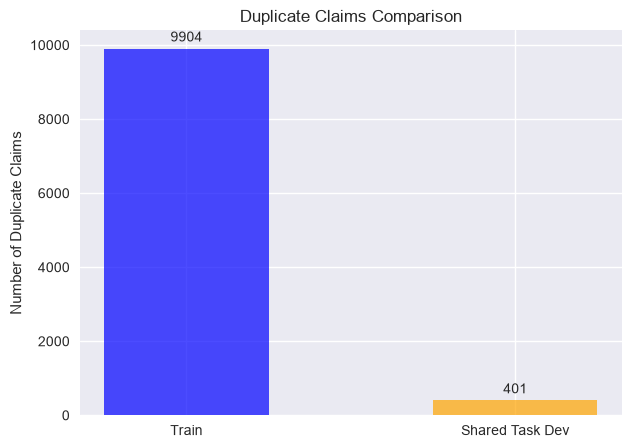

In [18]:
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8")

# Data: count of duplicate claims in each dataset
datasets = ["Train", "Shared Task Dev"]
dup_counts = [
    df_train.duplicated(subset=["claim"]).sum(),
    df_shared_task.duplicated(subset=["claim"]).sum(),
]

# Plot
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(datasets, dup_counts, color=["blue", "orange"], alpha=0.7, width=0.5)

ax.set_title("Duplicate Claims Comparison")
ax.set_ylabel("Number of Duplicate Claims")
ax.bar_label(bars, padding=3)

plt.show()